# Ноутбук 2 (Трек B): Табличные Foundation-Модели (`TabPFN`, `TabICLv2`, `TAG`), Граф-Таблицы (`G2T-FM`, `InductiveMVGAT`) и Deep Tabular (`TabR‡`, `T2G-Former`, `TabM†`)

**Архитектура экспериментов Трека B (строго на замороженных фолдах `Train_5x5_CV.json`):**
1. **Exp B1 (`TabPFN` + `TAG` — Subsampled Table Ensembling):** сравнение монолитной подачи признаков против ансамбля 5 ортогональных компактных витрин ($d \in [4, 6]$, включая `MS_Top4_NoAMBP` и `LUPI_ELISA`) + жадный/равномерный отбор витрин строго по `Train_5x5_CV`.
2. **Exp B2 (`TabICLv2` — циклические тройки `(0,1,3)` и `QASSMax`):** тестирование на компактных витринах и сбалансированной $m=10$-витрине (где по Теореме A.1 $m \ge 7$ ни одна пара признаков не повторяется дважды). Дополнительно — генерация 4-маркерного моста `bridge_cq_TFM.parquet` для Чунцина.
3. **Exp B3 (`G2T-FM` + `InductiveMVGAT` — индуктивный граф пациенток с защитой от сдвига превалентности):**
   - `B3a`: строго внутрифолдовый (`n=65`) пересчёт Nyström LapPE, RWSE, TabR-дельт и `Label Propagation` (с разделением target-free структуры и EM-скорректированного априора).
   - `B3b`: PyTorch `InductiveMVGAT` по 3 модальностям рёбер (`JSD, CLR, Mahal`) с нормировкой степени супер-хабов $d_{\text{in}}(j)^{-0.25}$.
4. **Exp B4 (`TabR‡` с `PLR(lite)` без $d^{-1/2}$):** обучение retrieval-нейросети с исключением самого объекта $i \notin I_{\text{cand}}(i)$ и веткой линейно-нелинейной экстраполяции $T(\Delta k)$ + гибридная версия с биофизическим якорем.
5. **Exp B5 (`T2G-Former` и `TabM†`):** `FR-Graph` + `Cross-level Readout` и параметрически-эффективный ансамбль `TabM-mini` ($k=32$) с `PLE (n_bins=5)` и `PeriodicEmbeddings`.

In [1]:
import os
import sys
import json
import zipfile
import shutil
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

os.system(f"{sys.executable} -m pip install -q tabpfn tabicl tabm rtdl_num_embeddings")

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.special import expit, logit, logsumexp

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    roc_curve,
)

from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tabicl import TabICLClassifier
from tabm import TabM
from rtdl_num_embeddings import (
    PeriodicEmbeddings,
    PiecewiseLinearEmbeddings,
    compute_bins,
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
})

print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | Device: cuda
GPU: NVIDIA L4


In [2]:
def unpack_archive_if_needed(zip_names: List[str], check_file: Path, target_dir: Path) -> Path:
    if check_file.exists():
        return target_dir
    for zname in zip_names:
        for base in [Path("."), Path("/content"), Path("/content/drive/MyDrive")]:
            zp = base / zname
            if zp.exists():
                target_dir.mkdir(parents=True, exist_ok=True)
                print(f"[UNZIP] {zp} -> {target_dir.resolve()}")
                with zipfile.ZipFile(zp, "r") as zf:
                    zf.extractall(target_dir)
                if check_file.exists():
                    return target_dir
                for found in target_dir.rglob(check_file.name):
                    return found.parents[len(check_file.relative_to(target_dir).parts) - 1]
    raise FileNotFoundError(f"Не найден {check_file} или архив из {zip_names}. Загрузите data.zip и artifacts.zip в /content/.")

DATA_DIR = unpack_archive_if_needed(["data.zip", "sptb_data.zip"], Path("./data/cohort_a_426_enriched.parquet"), Path("./data"))
ARTIFACTS_DIR = unpack_archive_if_needed(["artifacts.zip"], Path("./artifacts/splits/Train_5x5_CV.json"), Path("./artifacts"))

SPLITS_DIR = ARTIFACTS_DIR / "splits"
TRACK_A_DIR = ARTIFACTS_DIR / "track_a"
TRACK_B_DIR = ARTIFACTS_DIR / "track_b"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
for d in [TRACK_B_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

cohort_a = pd.read_parquet(DATA_DIR / "cohort_a_426_enriched.parquet")
dataset_features = pd.read_parquet(DATA_DIR / "dataset_features.parquet").set_index("Sample ID")
cohort_b = pd.read_parquet(DATA_DIR / "cohort_b_35_proteome_distilled.parquet")

with open(SPLITS_DIR / "Train_5x5_CV.json", "r", encoding="utf-8") as f:
    train_5x5_splits = json.load(f)

MARKERS_5 = ["AMBP", "FN1", "LUM", "TIMP1", "B2M"]
MARKERS_4_NO_AMBP = ["LUM", "FN1", "TIMP1", "B2M"]
MARKERS_4_BRIDGE = ["AMBP", "FN1", "LUM", "B2M"]

train_mask = (cohort_a["Dataset"] == "Train").values
holdout_mask = ~train_mask
holdout_indices = np.where(holdout_mask)[0]

y_all = cohort_a["Target"].values.astype(int)
y_train_82 = y_all[train_mask]
y_holdout = y_all[holdout_mask]
ds_holdout = cohort_a["Dataset"].values[holdout_mask]

m_int = ds_holdout == "Internal validation"
m_ext1 = ds_holdout == "External validation1"
m_ext2 = ds_holdout == "External validation2"
PI_TRAIN = float(np.mean(y_train_82))

assert (cohort_a.index[train_mask][train_5x5_splits[0]["train_pos"]].tolist() == train_5x5_splits[0]["train_sample_ids"]), "Рассинхронизация фолдов!"
print(f"[OK] Данные и 25 фолдов `Train_5x5_CV` загружены и проверены. Train={len(y_train_82)} (PTB={y_train_82.sum()}), Holdout={len(y_holdout)}.")

# --- Утилиты оценки и Saerens EM (идентично Ноутбуку 1) ---
def estimate_prior_saerens_em(probs: np.ndarray, pi_train: float, alpha_reg: float = 2.0, max_iter: int = 500, tol: float = 1e-6) -> float:
    p = np.clip(np.asarray(probs, dtype=float), 1e-6, 1.0 - 1e-6)
    n_c = len(p)
    pi_c = float(pi_train)
    for _ in range(max_iter):
        r1 = pi_c / pi_train
        r0 = (1.0 - pi_c) / (1.0 - pi_train)
        q = (p * r1) / (p * r1 + (1.0 - p) * r0 + 1e-12)
        pi_next = float(np.clip((np.sum(q) + alpha_reg * pi_train) / (n_c + alpha_reg), 0.03, 0.85))
        if abs(pi_next - pi_c) < tol:
            pi_c = pi_next
            break
        pi_c = pi_next
    return pi_c

def adjust_probs_saerens(probs: np.ndarray, pi_train: float, alpha_reg: float = 2.0) -> Tuple[np.ndarray, float]:
    p = np.clip(np.asarray(probs, dtype=float), 1e-6, 1.0 - 1e-6)
    pi_est = estimate_prior_saerens_em(p, pi_train=pi_train, alpha_reg=alpha_reg)
    z = logit(p)
    delta = np.log(pi_est / (1.0 - pi_est)) - np.log(pi_train / (1.0 - pi_train))
    return expit(z + delta), pi_est

def compute_clinical_metrics(y_true: np.ndarray, probs: np.ndarray, threshold: float = 0.3500) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    probs = np.clip(np.asarray(probs, dtype=float), 1e-7, 1.0 - 1e-7)
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {
        "AUROC": float(roc_auc_score(y_true, probs)),
        "AUPR": float(average_precision_score(y_true, probs)),
        "F1": float(f1_score(y_true, preds, zero_division=0)),
        "Sens": float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,
        "Spec": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,
        "PPV": float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0,
        "NPV": float(tn / (tn + fn)) if (tn + fn) > 0 else 0.0,
        "Brier": float(brier_score_loss(y_true, probs)),
        "LogLoss": float(log_loss(y_true, probs)),
    }

def delong_roc_test(y_true: np.ndarray, probs_a: np.ndarray, probs_b: np.ndarray) -> Tuple[float, float]:
    y_true = np.asarray(y_true, dtype=int)
    pos, neg = y_true == 1, y_true == 0
    m, n = int(np.sum(pos)), int(np.sum(neg))
    if m < 2 or n < 2:
        return 0.0, 1.0
    def _comp(scores):
        diff = scores[pos, None] - scores[None, neg]
        psi = np.where(diff > 0, 1.0, np.where(diff == 0, 0.5, 0.0))
        v10, v01 = np.mean(psi, axis=1), np.mean(psi, axis=0)
        return float(np.mean(v10)), v10, v01
    auc_a, v10_a, v01_a = _comp(np.asarray(probs_a, dtype=float))
    auc_b, v10_b, v01_b = _comp(np.asarray(probs_b, dtype=float))
    s = np.cov(np.vstack([v10_a, v10_b]), ddof=1) / m + np.cov(np.vstack([v01_a, v01_b]), ddof=1) / n
    var_diff = s[0, 0] + s[1, 1] - 2.0 * s[0, 1]
    if var_diff <= 1e-12:
        return 0.0, 1.0
    z_stat = (auc_a - auc_b) / np.sqrt(var_diff)
    return float(z_stat), float(2.0 * stats.norm.sf(abs(z_stat)))

def save_track_b_artifact(model_name: str, oof_logits: np.ndarray, test_logits_bagged: np.ndarray, test_logits_refit: Optional[np.ndarray] = None):
    oof_probs = expit(oof_logits)
    p_hold = expit(test_logits_bagged)
    p_hold_em = np.zeros_like(p_hold)
    for cmask in [m_int, m_ext1, m_ext2]:
        p_hold_em[cmask], _ = adjust_probs_saerens(p_hold[cmask], pi_train=PI_TRAIN, alpha_reg=2.0)

    p_refit = expit(test_logits_refit) if test_logits_refit is not None else p_hold.copy()

    pd.DataFrame({
        "Sample_ID": cohort_a.index[train_mask],
        "Target": y_train_82,
        "oof_prob": oof_probs,
        "oof_logit": oof_logits,
    }).set_index("Sample_ID").to_parquet(TRACK_B_DIR / f"oof_{model_name}.parquet")

    pd.DataFrame({
        "Sample_ID": cohort_a.index[holdout_mask],
        "Dataset": ds_holdout,
        "Target": y_holdout,
        "test_prob_bagged": p_hold,
        "test_logit_bagged": test_logits_bagged,
        "test_prob_refit": p_refit,
        "test_prob_bagged_saerens_em": p_hold_em,
    }).set_index("Sample_ID").to_parquet(TRACK_B_DIR / f"test_{model_name}.parquet")

[UNZIP] data.zip -> /content/data
[UNZIP] artifacts.zip -> /content/artifacts
[OK] Данные и 25 фолдов `Train_5x5_CV` загружены и проверены. Train=82 (PTB=27), Holdout=344.


In [3]:
class FoldHonestFTBGeometry:
    def __init__(self, tau: float = 0.5, clip_z: float = 5.0):
        self.tau = tau
        self.clip_z = clip_z

    def _fit_params(self, X_ftb: np.ndarray):
        mu = np.mean(X_ftb, axis=0)
        sd = np.where(np.std(X_ftb, axis=0, ddof=1) < 1e-6, 1.0, np.std(X_ftb, axis=0, ddof=1))
        lin = np.power(2.0, np.clip(X_ftb, -30.0, 30.0))
        Q_ftb = np.mean(lin / (np.sum(lin, axis=1, keepdims=True) + 1e-12), axis=0)
        Q_ftb = np.clip(Q_ftb, 1e-9, 1.0)
        Q_ftb /= np.sum(Q_ftb)
        omega = LedoitWolf(store_precision=True).fit(X_ftb).precision_
        omega_off = omega - np.diag(np.diag(omega))
        return mu, sd, Q_ftb, omega, omega_off

    def _compute(self, X_5: np.ndarray, mu, sd, Q_ftb, omega, omega_off) -> np.ndarray:
        lin = np.power(2.0, np.clip(X_5, -30.0, 30.0))
        P = np.clip(lin / (np.sum(lin, axis=1, keepdims=True) + 1e-12), 1e-12, 1.0)
        P /= np.sum(P, axis=1, keepdims=True)
        M = 0.5 * (P + Q_ftb[None, :])
        jsd = np.clip(0.5 * (np.sum(P * np.log2(P / M), axis=1) + np.sum(Q_ftb[None, :] * np.log2(Q_ftb[None, :] / M), axis=1)), 0.0, None)
        U = (X_5 - mu[None, :]) / sd[None, :]
        lse_max = self.tau * logsumexp(U / self.tau, axis=1)
        total_burden = np.mean(U, axis=1)
        diff = X_5 - mu[None, :]
        mahal_dist = np.sqrt(np.clip(np.einsum("ni,ij,nj->n", diff, omega, diff), 0.0, None))
        decoupling = np.einsum("ni,ij,nj->n", diff, omega_off, diff)
        return np.column_stack([lse_max, mahal_dist, decoupling, jsd, total_burden])

    def fit_transform_fold(self, X_tr: np.ndarray, y_tr: np.ndarray, X_val: np.ndarray, X_hold: np.ndarray):
        ftb_idx = np.where(y_tr == 0)[0]
        X_ftb = X_tr[ftb_idx]
        params = self._fit_params(X_ftb)
        F_tr = self._compute(X_tr, *params)
        if len(ftb_idx) > 5:
            for k, row_i in enumerate(ftb_idx):
                p_loo = self._fit_params(np.delete(X_ftb, k, axis=0))
                F_tr[row_i : row_i + 1] = self._compute(X_tr[row_i : row_i + 1], *p_loo)
        F_val = self._compute(X_val, *params)
        F_hold = self._compute(X_hold, *params)
        sc = RobustScaler()
        return (
            np.clip(sc.fit_transform(F_tr), -self.clip_z, self.clip_z),
            np.clip(sc.transform(F_val), -self.clip_z, self.clip_z),
            np.clip(sc.transform(F_hold), -self.clip_z, self.clip_z),
        )


def compute_fold_inductive_graph_pack(
    X_all_5: np.ndarray,
    y_all_vec: np.ndarray,
    support_global_indices: np.ndarray,
    k_neighbors: int = 8,
    n_lappe: int = 4,
    deg_beta: float = 0.25,
) -> Dict[str, np.ndarray]:
    n_total = X_all_5.shape[0]
    n_ref = len(support_global_indices)
    X_ref = X_all_5[support_global_indices]
    y_ref = y_all_vec[support_global_indices].astype(float)

    lin_all = np.power(2.0, np.clip(X_all_5, -30.0, 30.0))
    P_all = np.clip(lin_all / (np.sum(lin_all, axis=1, keepdims=True) + 1e-12), 1e-12, 1.0)
    P_all /= np.sum(P_all, axis=1, keepdims=True)
    P_ref = P_all[support_global_indices]

    clr_all = X_all_5 - np.mean(X_all_5, axis=1, keepdims=True)
    clr_norm = clr_all / (np.linalg.norm(clr_all, axis=1, keepdims=True) + 1e-12)
    clr_ref = clr_norm[support_global_indices]

    mu_r = np.mean(X_ref, axis=0)
    sd_r = np.where(np.std(X_ref, axis=0, ddof=1) < 1e-6, 1.0, np.std(X_ref, axis=0, ddof=1))
    X_std = (X_all_5 - mu_r) / sd_r
    X_ref_std = X_std[support_global_indices]
    omega_tr = LedoitWolf(store_precision=True).fit(X_ref_std).precision_

    d_jsd = np.zeros((n_total, n_ref))
    for j in range(n_ref):
        m_p = 0.5 * (P_all + P_ref[j : j + 1])
        d_jsd[:, j] = np.sqrt(np.clip(0.5 * (
            np.sum(P_all * np.log2(P_all / m_p), axis=1) +
            np.sum(P_ref[j : j + 1] * np.log2(P_ref[j : j + 1] / m_p), axis=1)
        ), 0.0, None))
    d_clr = np.clip(1.0 - clr_norm @ clr_ref.T, 0.0, 2.0)
    diff_m = X_std[:, None, :] - X_ref_std[None, :, :]
    d_mah = np.sqrt(np.clip(np.einsum("nri,ij,nrj->nr", diff_m, omega_tr, diff_m), 0.0, None))

    sup_map = {int(g_i): loc_j for loc_j, g_i in enumerate(support_global_indices)}
    med_j = float(np.median(d_jsd[d_jsd > 0])) + 1e-8
    med_c = float(np.median(d_clr[d_clr > 0])) + 1e-8
    med_m = float(np.median(d_mah[d_mah > 0])) + 1e-8

    d_prim = 0.40 * (d_jsd / med_j) + 0.30 * (d_clr / med_c) + 0.30 * (d_mah / med_m)
    for g_i, loc_j in sup_map.items():
        d_prim[g_i, loc_j] = np.inf

    k_eff = min(k_neighbors, n_ref - 1)
    nbr_idx = np.argpartition(d_prim, kth=k_eff - 1, axis=1)[:, :k_eff]

    def _gaussian_view_weights(dist_mat: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        dist_nbr = np.take_along_axis(dist_mat, nbr_idx, axis=1)
        sig_i = np.max(dist_nbr, axis=1) + 1e-6
        d_ref_nbr = np.take_along_axis(dist_mat[support_global_indices], nbr_idx[support_global_indices], axis=1)
        sig_j = np.max(d_ref_nbr, axis=1) + 1e-6
        W_v = np.zeros((n_total, n_ref))
        for i in range(n_total):
            nb = nbr_idx[i]
            w = np.maximum(np.exp(-(dist_mat[i, nb] ** 2) / (2.0 * sig_i[i] * sig_j[nb])), 1e-3)
            W_v[i, nb] = w
        in_deg = np.sum(W_v > 0, axis=0) + 1.0
        W_v_deg = W_v / (in_deg[None, :] ** deg_beta)
        A_v = W_v_deg / (np.sum(W_v_deg, axis=1, keepdims=True) + 1e-12)
        return W_v, A_v

    W_jsd, A_jsd = _gaussian_view_weights(d_jsd)
    W_clr, A_clr = _gaussian_view_weights(d_clr)
    W_mah, A_mah = _gaussian_view_weights(d_mah)
    A_comb = (A_jsd + A_clr + A_mah) / 3.0

    W_tr_raw = (W_jsd[support_global_indices] + W_clr[support_global_indices] + W_mah[support_global_indices]) / 3.0
    W_tr_sym = 0.5 * (W_tr_raw + W_tr_raw.T)
    np.fill_diagonal(W_tr_sym, 0.0)
    deg_tr = np.sum(W_tr_sym, axis=1)
    d_inv_sqrt = np.where(deg_tr > 1e-8, 1.0 / np.sqrt(deg_tr + 1e-8), 0.0)
    L_sym = np.eye(n_ref) - (d_inv_sqrt[:, None] * W_tr_sym * d_inv_sqrt[None, :])
    eigvals, eigvecs = np.linalg.eigh(L_sym)

    start_k = 1
    end_k = min(start_k + n_lappe, n_ref)
    lam_k = np.maximum(eigvals[start_k:end_k], 1e-3)
    psi_tr = eigvecs[:, start_k:end_k]

    signs = np.where(np.sum(psi_tr, axis=0) >= 0, 1.0, -1.0)
    psi_tr = psi_tr * signs[None, :]
    lap_pe_all = (A_comb @ psi_tr) / lam_k[None, :]

    lap_pe_all[support_global_indices] = psi_tr


    A_tr = A_comb[support_global_indices]
    rw1 = A_comb
    rw2 = A_comb @ A_tr
    rw1_clip = np.clip(rw1, 1e-12, 1.0)
    rw2_clip = np.clip(rw2, 1e-12, 1.0)
    rw1_ent = -np.sum(np.where(rw1 > 1e-12, rw1 * np.log(rw1_clip), 0.0), axis=1)
    rw2_ent = -np.sum(np.where(rw2 > 1e-12, rw2 * np.log(rw2_clip), 0.0), axis=1)
    rw1_max = np.max(rw1, axis=1)


    tabr_delta1 = X_all_5 - (A_comb @ X_ref)
    local_density = np.mean(W_jsd[np.arange(n_total)[:, None], nbr_idx], axis=1)

    target_free_feats = np.column_stack([
        lap_pe_all,
        rw1_ent, rw2_ent, rw1_max, local_density,
        tabr_delta1,
    ])


    lp_probs = np.clip(A_comb @ y_ref, 1e-4, 1.0 - 1e-4)

    return {
        "target_free_feats": target_free_feats,
        "lp_probs": lp_probs,
        "A_views": np.stack([A_jsd, A_clr, A_mah], axis=0),
        "A_comb": A_comb,
        "nbr_idx": nbr_idx,
    }

print("[OK] Индуктивный генератор графовых и FTB-признаков инициализирован.")

[OK] Индуктивный генератор графовых и FTB-признаков инициализирован.


In [4]:
def get_hf_token() -> Optional[str]:
    tok = os.environ.get("HF_TOKEN", None)
    if tok:
        return tok
    try:
        from google.colab import userdata
        tok = userdata.get("HF_TOKEN")
        if tok:
            os.environ["HF_TOKEN"] = tok
            return tok
    except Exception:
        pass
    return None

HF_TOKEN = get_hf_token()

def build_tabpfn(n_estimators: int = 16, softmax_temperature: float = 0.9):
    if HF_TOKEN:
        try:
            clf = TabPFNClassifier.create_default_for_version(
                ModelVersion.V2_5,
                n_estimators=n_estimators,
                softmax_temperature=softmax_temperature,
                device=DEVICE_STR,
                random_state=SEED,
            )
            return clf, "TabPFN-v2.5"
        except Exception as e:
            print(f"[INFO] TabPFN-v2.5 недоступен ({type(e).__name__}), переключаюсь на открытый TabPFN-v2...")
    clf = TabPFNClassifier.create_default_for_version(
        ModelVersion.V2,
        n_estimators=n_estimators,
        softmax_temperature=softmax_temperature,
        device=DEVICE_STR,
        random_state=SEED,
    )
    return clf, "TabPFN-v2"

def build_tabicl(n_estimators: int = 16, softmax_temperature: float = 0.9):
    clf = TabICLClassifier(
        n_estimators=n_estimators,
        feat_shuffle_method="latin",
        class_shuffle_method="shift",
        outlier_threshold=4.0,
        softmax_temperature=softmax_temperature,
        average_logits=True,
        random_state=SEED,
        device=DEVICE_STR,
    )
    return clf, "TabICLv2"


_tpfn_probe, TABPFN_VER_NAME = build_tabpfn(n_estimators=8)
_ticl_probe, TABICL_VER_NAME = build_tabicl(n_estimators=8)
_X_dummy = np.random.randn(20, 5).astype(np.float32)
_y_dummy = np.array([0]*10 + [1]*10)
_tpfn_probe.fit(_X_dummy, _y_dummy)
_ = _tpfn_probe.predict_proba(_X_dummy[:4])
_ticl_probe.fit(_X_dummy, _y_dummy)
_ = _ticl_probe.predict_proba(_X_dummy[:4])
print(f"[CHECKPOINTS READY] {TABPFN_VER_NAME} и {TABICL_VER_NAME} успешно загружены на {DEVICE_STR}!")


X_aligned_all = cohort_a[MARKERS_5].values
X_noambp_all = cohort_a[MARKERS_4_NO_AMBP].values
X_bridge4_all = cohort_a[MARKERS_4_BRIDGE].values
X_lupi_all = cohort_a[[f"elisa_denoised_{m}" for m in MARKERS_5] + ["elisa_tech_shift_delta"]].values
X_stoich_all = cohort_a[["idx_ECM_Stress", "idx_Subtype_Polarization_SPI", "ratio_B2M_LUM", "clr_LUM", "clr_B2M"]].values

def run_tfm_view_cv(view_name: str, model_kind: str, view_builder_fn, n_estimators: int = 16):
    n_tr = len(y_train_82)
    oof_logits_rep = np.zeros((n_tr, 5))
    test_logits_25 = np.zeros((len(y_holdout), len(train_5x5_splits)))
    fold_aucs, fold_losses = [], []

    for sp in train_5x5_splits:
        s_id, rep = sp["split_id"], sp["repeat"]
        tr_pos = np.array(sp["train_pos"], dtype=int)
        val_pos = np.array(sp["val_pos"], dtype=int)

        X_tr, X_val, X_hold = view_builder_fn(tr_pos, val_pos, holdout_indices)
        y_tr, y_val = y_train_82[tr_pos], y_train_82[val_pos]


        sc = StandardScaler()
        X_tr_s = np.clip(sc.fit_transform(X_tr), -5.0, 5.0).astype(np.float32)
        X_val_s = np.clip(sc.transform(X_val), -5.0, 5.0).astype(np.float32)
        X_hold_s = np.clip(sc.transform(X_hold), -5.0, 5.0).astype(np.float32)

        clf, _ = build_tabpfn(n_estimators=n_estimators) if model_kind == "TabPFN" else build_tabicl(n_estimators=n_estimators)
        clf.fit(X_tr_s, y_tr)
        p_val = np.clip(clf.predict_proba(X_val_s)[:, 1], 1e-6, 1.0 - 1e-6)
        p_hold = np.clip(clf.predict_proba(X_hold_s)[:, 1], 1e-6, 1.0 - 1e-6)

        oof_logits_rep[val_pos, rep] = logit(p_val)
        test_logits_25[:, s_id] = logit(p_hold)
        fold_aucs.append(roc_auc_score(y_val, p_val))
        fold_losses.append(log_loss(y_val, p_val))

    oof_logits = np.mean(oof_logits_rep, axis=1)
    test_logits_bagged = np.mean(test_logits_25, axis=1)


    all_tr = np.arange(n_tr)
    X_82, _, X_hold_82 = view_builder_fn(all_tr, all_tr, holdout_indices)
    sc82 = StandardScaler()
    X_82_s = np.clip(sc82.fit_transform(X_82), -5.0, 5.0).astype(np.float32)
    X_hold_82_s = np.clip(sc82.transform(X_hold_82), -5.0, 5.0).astype(np.float32)
    clf82, _ = build_tabpfn(n_estimators=n_estimators) if model_kind == "TabPFN" else build_tabicl(n_estimators=n_estimators)
    clf82.fit(X_82_s, y_train_82)
    test_logits_refit = logit(np.clip(clf82.predict_proba(X_hold_82_s)[:, 1], 1e-6, 1.0 - 1e-6))

    return {
        "view": view_name,
        "model": model_kind,
        "cv_auroc": float(np.mean(fold_aucs)),
        "cv_auroc_sd": float(np.std(fold_aucs)),
        "oof_metrics": compute_clinical_metrics(y_train_82, expit(oof_logits)),
        "oof_logits": oof_logits,
        "test_logits_bagged": test_logits_bagged,
        "test_logits_refit": test_logits_refit,
        "fitted_82": (clf82, sc82),
    }

def vb_v1_core5(tr, val, hold): return X_aligned_all[tr], X_aligned_all[val], X_aligned_all[hold]
def vb_v2_noambp4(tr, val, hold): return X_noambp_all[tr], X_noambp_all[val], X_noambp_all[hold]
def vb_v3_lupi6(tr, val, hold): return X_lupi_all[tr], X_lupi_all[val], X_lupi_all[hold]
def vb_v4_nonlin5(tr, val, hold):
    g = FoldHonestFTBGeometry()
    return g.fit_transform_fold(X_aligned_all[tr], y_train_82[tr], X_aligned_all[val], X_aligned_all[hold])
def vb_v5_stoich5(tr, val, hold): return X_stoich_all[tr], X_stoich_all[val], X_stoich_all[hold]
def vb_m10_compact(tr, val, hold):
    g_tr, g_val, g_hold = vb_v4_nonlin5(tr, val, hold)

    s_tr = X_stoich_all[tr, :2]
    s_val = X_stoich_all[val, :2]
    s_hold = X_stoich_all[hold, :2]
    return np.hstack([X_aligned_all[tr], g_tr[:, :3], s_tr]), np.hstack([X_aligned_all[val], g_val[:, :3], s_val]), np.hstack([X_aligned_all[hold], g_hold[:, :3], s_hold])
def vb_bridge4(tr, val, hold): return X_bridge4_all[tr], X_bridge4_all[val], X_bridge4_all[hold]

tfm_views = [
    ("V1_Core5", vb_v1_core5),
    ("V2_NoAMBP4", vb_v2_noambp4),
    ("V3_LUPI6", vb_v3_lupi6),
    ("V4_Nonlin5", vb_v4_nonlin5),
    ("V5_Stoich5", vb_v5_stoich5),
    ("M10_Compact_Triples", vb_m10_compact),
    ("Bridge4_NoTIMP1", vb_bridge4),
]

tfm_results = {}
rows_b1_b2 = []

for m_kind in ["TabPFN", "TabICLv2"]:
    for v_name, v_fn in tfm_views:
        r = run_tfm_view_cv(v_name, m_kind, v_fn, n_estimators=16)
        tfm_results[f"{m_kind}__{v_name}"] = r
        rows_b1_b2.append({
            "Model": m_kind,
            "View": v_name,
            "CV_AUROC": round(r["cv_auroc"], 4),
            "OOF_AUROC": round(r["oof_metrics"]["AUROC"], 4),
            "OOF_AUPR": round(r["oof_metrics"]["AUPR"], 4),
            "OOF_LogLoss": round(r["oof_metrics"]["LogLoss"], 4),
            "OOF_Brier": round(r["oof_metrics"]["Brier"], 4),
        })


tag_view_keys = ["V1_Core5", "V2_NoAMBP4", "V3_LUPI6", "V4_Nonlin5", "V5_Stoich5"]
for m_kind in ["TabPFN", "TabICLv2"]:

    oof_stack = np.column_stack([tfm_results[f"{m_kind}__{v}"]["oof_logits"] for v in tag_view_keys])
    test_bag_stack = np.column_stack([tfm_results[f"{m_kind}__{v}"]["test_logits_bagged"] for v in tag_view_keys])
    test_ref_stack = np.column_stack([tfm_results[f"{m_kind}__{v}"]["test_logits_refit"] for v in tag_view_keys])

    tag_eq_oof = np.mean(oof_stack, axis=1)
    tag_eq_bag = np.mean(test_bag_stack, axis=1)
    tag_eq_ref = np.mean(test_ref_stack, axis=1)
    met_eq = compute_clinical_metrics(y_train_82, expit(tag_eq_oof))

    tfm_results[f"{m_kind}__TAG_Equal_5Views"] = {
        "oof_logits": tag_eq_oof, "test_logits_bagged": tag_eq_bag, "test_logits_refit": tag_eq_ref, "oof_metrics": met_eq
    }
    rows_b1_b2.append({
        "Model": m_kind, "View": "TAG_Equal_5Views", "CV_AUROC": np.nan,
        "OOF_AUROC": round(met_eq["AUROC"], 4), "OOF_AUPR": round(met_eq["AUPR"], 4),
        "OOF_LogLoss": round(met_eq["LogLoss"], 4), "OOF_Brier": round(met_eq["Brier"], 4),
    })


    selected_idx = []
    best_loss = 1e9
    for _ in range(10):
        best_cand, cand_loss = None, best_loss
        for j in range(len(tag_view_keys)):
            cur = selected_idx + [j]
            avg_l = np.mean(oof_stack[:, cur], axis=1)
            ll = log_loss(y_train_82, expit(avg_l))
            if ll < cand_loss - 1e-5:
                cand_loss = ll
                best_cand = j
        if best_cand is not None:
            selected_idx.append(best_cand)
            best_loss = cand_loss
        else:
            break
    if not selected_idx:
        selected_idx = [0, 1]
    weights_tag = np.bincount(selected_idx, minlength=len(tag_view_keys)).astype(float)
    weights_tag /= np.sum(weights_tag)

    tag_es_oof = oof_stack @ weights_tag
    tag_es_bag = test_bag_stack @ weights_tag
    tag_es_ref = test_ref_stack @ weights_tag
    met_es = compute_clinical_metrics(y_train_82, expit(tag_es_oof))

    tfm_results[f"{m_kind}__TAG_ES_5Views"] = {
        "oof_logits": tag_es_oof, "test_logits_bagged": tag_es_bag, "test_logits_refit": tag_es_ref, "oof_metrics": met_es
    }
    print(f"[TAG ES Weights for {m_kind}] {dict(zip(tag_view_keys, weights_tag.round(3)))}")
    rows_b1_b2.append({
        "Model": m_kind, "View": "TAG_ES_5Views", "CV_AUROC": np.nan,
        "OOF_AUROC": round(met_es["AUROC"], 4), "OOF_AUPR": round(met_es["AUPR"], 4),
        "OOF_LogLoss": round(met_es["LogLoss"], 4), "OOF_Brier": round(met_es["Brier"], 4),
    })

df_b1_b2 = pd.DataFrame(rows_b1_b2)
print("\n=== РЕЗУЛЬТАТЫ EXP B1 & B2 (TabPFN + TAG и TabICLv2 НА TRAIN_5x5_CV) ===")
print(df_b1_b2.to_string(index=False))


X_cq_bridge4 = cohort_b[[f"aligned_4marker_{m}" for m in MARKERS_4_BRIDGE]].values
cq_preds = {}
for m_kind in ["TabPFN", "TabICLv2"]:
    clf82, sc82 = tfm_results[f"{m_kind}__Bridge4_NoTIMP1"]["fitted_82"]
    X_cq_s = np.clip(sc82.transform(X_cq_bridge4), -5.0, 5.0).astype(np.float32)
    p_cq = np.clip(clf82.predict_proba(X_cq_s)[:, 1], 1e-6, 1.0 - 1e-6)
    cq_preds[m_kind] = p_cq

p_cq_tfm_mean = expit(0.5 * (logit(cq_preds["TabPFN"]) + logit(cq_preds["TabICLv2"])))
p_cq_tfm_std = np.std(np.column_stack([cq_preds["TabPFN"], cq_preds["TabICLv2"]]), axis=1)
pd.DataFrame({
    "Sample_ID": cohort_b.index,
    "sPTB_Prob_TFM": p_cq_tfm_mean,
    "sPTB_Logit_TFM": logit(p_cq_tfm_mean),
    "sPTB_Prob_TabPFN": cq_preds["TabPFN"],
    "sPTB_Prob_TabICLv2": cq_preds["TabICLv2"],
    "Uncertainty_Std_TFM": p_cq_tfm_std,
}).set_index("Sample_ID").to_parquet(TRACK_B_DIR / "bridge_cq_TFM.parquet")
print("[SAVED BRIDGE] `bridge_cq_TFM.parquet` для Чунцина (35x6) готов!")

tabpfn-v2-classifier-finetuned-zk73skhh.(…): reconstructing file:   0%|          |  0.00B / 29.0MB            

tabpfn-v2-classifier-finetuned-zk73skhh.(…): downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.



tabicl-classifier-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  110MB            

tabicl-classifier-v2-20260212.ckpt: downloading bytes:           |  0.00B            

[CHECKPOINTS READY] TabPFN-v2 и TabICLv2 успешно загружены на cuda!
[TAG ES Weights for TabPFN] {'V1_Core5': np.float64(0.0), 'V2_NoAMBP4': np.float64(0.0), 'V3_LUPI6': np.float64(0.0), 'V4_Nonlin5': np.float64(1.0), 'V5_Stoich5': np.float64(0.0)}
[TAG ES Weights for TabICLv2] {'V1_Core5': np.float64(0.0), 'V2_NoAMBP4': np.float64(0.667), 'V3_LUPI6': np.float64(0.0), 'V4_Nonlin5': np.float64(0.333), 'V5_Stoich5': np.float64(0.0)}

=== РЕЗУЛЬТАТЫ EXP B1 & B2 (TabPFN + TAG и TabICLv2 НА TRAIN_5x5_CV) ===
   Model                View  CV_AUROC  OOF_AUROC  OOF_AUPR  OOF_LogLoss  OOF_Brier
  TabPFN            V1_Core5    0.9176     0.9017    0.7718       0.3910     0.1068
  TabPFN          V2_NoAMBP4    0.9165     0.9098    0.7813       0.3789     0.1054
  TabPFN            V3_LUPI6    0.9194     0.9024    0.7776       0.3918     0.1079
  TabPFN          V4_Nonlin5    0.9282     0.9205    0.7817       0.3485     0.1082
  TabPFN          V5_Stoich5    0.8480     0.8121    0.6630       0.4758

In [6]:
class InductiveMVGAT(nn.Module):
    def __init__(self, n_features: int, d_hid: int = 24, dropout: float = 0.40):
        super().__init__()
        self.node_enc = nn.Sequential(
            nn.Linear(n_features, d_hid),
            nn.LayerNorm(d_hid),
            nn.SiLU(),
            nn.Dropout(dropout),
        )
        self.view_logits = nn.Parameter(torch.zeros(3))
        self.y_emb = nn.Embedding(2, d_hid)
        self.delta_mlp = nn.Sequential(
            nn.Linear(n_features, d_hid),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(d_hid, d_hid, bias=False),
        )
        self.head = nn.Sequential(
            nn.LayerNorm(d_hid * 2),
            nn.Dropout(dropout),
            nn.Linear(d_hid * 2, 1),
        )

    def forward(self, x_q, x_ref, y_ref, A_views_q):

        w_views = F.softmax(self.view_logits, dim=0)
        A_comb = torch.einsum("v,vbn->bn", w_views, A_views_q)

        h_q = self.node_enc(x_q)
        h_ref = self.node_enc(x_ref) + self.y_emb(y_ref)
        msg_nbr = torch.matmul(A_comb, h_ref)

        x_nbr_avg = torch.matmul(A_comb, x_ref)
        delta_msg = self.delta_mlp(x_q - x_nbr_avg)

        out = self.head(torch.cat([h_q + delta_msg, msg_nbr], dim=-1)).squeeze(-1)
        return out


def run_exp_b3_graph_models():
    n_tr = len(y_train_82)

    oof_g2t_tpfn = np.zeros((n_tr, 5))
    oof_g2t_ticl = np.zeros((n_tr, 5))
    oof_lp_raw = np.zeros((n_tr, 5))
    oof_mvgat = np.zeros((n_tr, 5))

    test_g2t_tpfn = np.zeros((len(y_holdout), len(train_5x5_splits)))
    test_g2t_ticl = np.zeros((len(y_holdout), len(train_5x5_splits)))
    test_lp_raw = np.zeros((len(y_holdout), len(train_5x5_splits)))
    test_mvgat = np.zeros((len(y_holdout), len(train_5x5_splits)))

    mvgat_train_curves, mvgat_val_curves = [], []

    for sp in train_5x5_splits:
        s_id, rep = sp["split_id"], sp["repeat"]
        tr_pos = np.array(sp["train_pos"], dtype=int)
        val_pos = np.array(sp["val_pos"], dtype=int)


        g_pack = compute_fold_inductive_graph_pack(X_aligned_all, y_all, support_global_indices=tr_pos, k_neighbors=8, n_lappe=4, deg_beta=0.25)
        tf_feats = g_pack["target_free_feats"]
        lp_probs = g_pack["lp_probs"]

        oof_lp_raw[val_pos, rep] = logit(lp_probs[val_pos])
        test_lp_raw[:, s_id] = logit(lp_probs[holdout_indices])


        sel_tf = [0, 1, 2, 3, 4, 7, 9, 10, 12]
        X_g2t_all = np.hstack([X_aligned_all, tf_feats[:, sel_tf]])
        sc = StandardScaler()
        X_tr_g = np.clip(sc.fit_transform(X_g2t_all[tr_pos]), -5.0, 5.0).astype(np.float32)
        X_val_g = np.clip(sc.transform(X_g2t_all[val_pos]), -5.0, 5.0).astype(np.float32)
        X_hold_g = np.clip(sc.transform(X_g2t_all[holdout_indices]), -5.0, 5.0).astype(np.float32)

        clf_pfn, _ = build_tabpfn(n_estimators=16)
        clf_pfn.fit(X_tr_g, y_train_82[tr_pos])
        oof_g2t_tpfn[val_pos, rep] = logit(np.clip(clf_pfn.predict_proba(X_val_g)[:, 1], 1e-6, 1.0 - 1e-6))
        test_g2t_tpfn[:, s_id] = logit(np.clip(clf_pfn.predict_proba(X_hold_g)[:, 1], 1e-6, 1.0 - 1e-6))

        clf_icl, _ = build_tabicl(n_estimators=16)
        clf_icl.fit(X_tr_g, y_train_82[tr_pos])
        oof_g2t_ticl[val_pos, rep] = logit(np.clip(clf_icl.predict_proba(X_val_g)[:, 1], 1e-6, 1.0 - 1e-6))
        test_g2t_ticl[:, s_id] = logit(np.clip(clf_icl.predict_proba(X_hold_g)[:, 1], 1e-6, 1.0 - 1e-6))


        torch.manual_seed(SEED + s_id)
        sc_g = StandardScaler()
        x_tr_t = torch.tensor(np.clip(sc_g.fit_transform(X_aligned_all[tr_pos]), -5.0, 5.0), dtype=torch.float32, device=DEVICE)
        x_val_t = torch.tensor(np.clip(sc_g.transform(X_aligned_all[val_pos]), -5.0, 5.0), dtype=torch.float32, device=DEVICE)
        x_hold_t = torch.tensor(np.clip(sc_g.transform(X_aligned_all[holdout_indices]), -5.0, 5.0), dtype=torch.float32, device=DEVICE)
        y_tr_t = torch.tensor(y_train_82[tr_pos], dtype=torch.float32, device=DEVICE)
        y_tr_long = y_tr_t.long()
        y_val_t = torch.tensor(y_train_82[val_pos], dtype=torch.float32, device=DEVICE)

        A_views = torch.tensor(g_pack["A_views"], dtype=torch.float32, device=DEVICE)
        A_tr = A_views[:, tr_pos, :]
        A_val = A_views[:, val_pos, :]
        A_hold = A_views[:, holdout_indices, :]

        model_gat = InductiveMVGAT(n_features=5, d_hid=20, dropout=0.40).to(DEVICE)
        opt = torch.optim.AdamW(model_gat.parameters(), lr=3e-3, weight_decay=2e-2)
        best_vloss = 1e9
        best_val_l, best_hold_l = None, None
        tr_hist, val_hist = [], []

        for ep in range(120):
            model_gat.train()
            opt.zero_grad()
            logits_tr = model_gat(x_tr_t, x_tr_t, y_tr_long, A_tr)
            loss_tr = F.binary_cross_entropy_with_logits(logits_tr, y_tr_t)
            loss_tr.backward()
            opt.step()

            model_gat.eval()
            with torch.no_grad():
                logits_v = model_gat(x_val_t, x_tr_t, y_tr_long, A_val)
                loss_v = F.binary_cross_entropy_with_logits(logits_v, y_val_t).item()
                tr_hist.append(loss_tr.item())
                val_hist.append(loss_v)
                if ep >= 15 and loss_v < best_vloss:
                    best_vloss = loss_v
                    best_val_l = logits_v.detach().cpu().numpy()
                    best_hold_l = model_gat(x_hold_t, x_tr_t, y_tr_long, A_hold).detach().cpu().numpy()

        oof_mvgat[val_pos, rep] = best_val_l
        test_mvgat[:, s_id] = best_hold_l
        mvgat_train_curves.append(tr_hist)
        mvgat_val_curves.append(val_hist)


    oof_tpfn_mean = np.mean(oof_g2t_tpfn, axis=1)
    oof_ticl_mean = np.mean(oof_g2t_ticl, axis=1)
    oof_lp_mean = np.mean(oof_lp_raw, axis=1)
    oof_mvgat_mean = np.mean(oof_mvgat, axis=1)

    test_tpfn_bag = np.mean(test_g2t_tpfn, axis=1)
    test_ticl_bag = np.mean(test_g2t_ticl, axis=1)
    test_lp_bag = np.mean(test_lp_raw, axis=1)
    test_mvgat_bag = np.mean(test_mvgat, axis=1)


    test_lp_em_logits = np.zeros_like(test_lp_bag)
    for cmask in [m_int, m_ext1, m_ext2]:
        p_adj, _ = adjust_probs_saerens(expit(test_lp_bag[cmask]), pi_train=PI_TRAIN, alpha_reg=2.0)
        test_lp_em_logits[cmask] = logit(np.clip(p_adj, 1e-6, 1.0 - 1e-6))


    oof_g2t_plus_lp = 0.75 * oof_tpfn_mean + 0.25 * oof_lp_mean
    test_g2t_plus_lp = 0.75 * test_tpfn_bag + 0.25 * test_lp_em_logits

    b3_dict = {
        "G2T_FM_TabPFN": (oof_tpfn_mean, test_tpfn_bag),
        "G2T_FM_TabICLv2": (oof_ticl_mean, test_ticl_bag),
        "Graph_LP_Only": (oof_lp_mean, test_lp_bag),
        "G2T_FM_plus_ShiftedLP": (oof_g2t_plus_lp, test_g2t_plus_lp),
        "InductiveMVGAT": (oof_mvgat_mean, test_mvgat_bag),
    }

    rows_b3 = []
    for name, (o_l, _) in b3_dict.items():
        met = compute_clinical_metrics(y_train_82, expit(o_l))
        rows_b3.append({
            "Model": name,
            "OOF_AUROC": round(met["AUROC"], 4),
            "OOF_AUPR": round(met["AUPR"], 4),
            "OOF_LogLoss": round(met["LogLoss"], 4),
            "OOF_Brier": round(met["Brier"], 4),
        })
    print("\n=== РЕЗУЛЬТАТЫ EXP B3 (G2T-FM И INDUCTIVE MVGAT НА TRAIN_5x5_CV) ===")
    print(pd.DataFrame(rows_b3).to_string(index=False))
    return b3_dict, (np.mean(mvgat_train_curves, axis=0), np.mean(mvgat_val_curves, axis=0))

b3_results, mvgat_curves = run_exp_b3_graph_models()


=== РЕЗУЛЬТАТЫ EXP B3 (G2T-FM И INDUCTIVE MVGAT НА TRAIN_5x5_CV) ===
                Model  OOF_AUROC  OOF_AUPR  OOF_LogLoss  OOF_Brier
        G2T_FM_TabPFN     0.8943    0.7670       0.3814     0.1122
      G2T_FM_TabICLv2     0.9192    0.7930       0.3538     0.1012
        Graph_LP_Only     0.8667    0.7528       0.6421     0.1351
G2T_FM_plus_ShiftedLP     0.8835    0.7512       0.4177     0.1203
       InductiveMVGAT     0.9455    0.8928       0.3065     0.0967


In [8]:
class TabRShiftRobust(nn.Module):
    def __init__(self, n_features: int, d_emb: int = 8, n_freq: int = 24, d_main: int = 24, att_dropout: float = 0.35, ffn_dropout: float = 0.40):
        super().__init__()
        self.num_emb = PeriodicEmbeddings(
            n_features=n_features,
            d_embedding=d_emb,
            n_frequencies=n_freq,
            frequency_init_scale=0.05,
            activation=True,
            lite=True,
        )
        self.key_enc = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.LayerNorm(n_features * d_emb),
            nn.Linear(n_features * d_emb, d_main),
            nn.ReLU(),
            nn.Dropout(ffn_dropout),
            nn.Linear(d_main, d_main),
        )
        self.y_emb = nn.Embedding(2, d_main)
        self.T_net = nn.Sequential(
            nn.Linear(d_main, d_main),
            nn.ReLU(),
            nn.Dropout(ffn_dropout),
            nn.Linear(d_main, d_main, bias=False),
        )
        self.att_drop = nn.Dropout(att_dropout)
        self.head = nn.Sequential(
            nn.LayerNorm(d_main),
            nn.ReLU(),
            nn.Linear(d_main, 1),
        )

    def encode_keys(self, x: torch.Tensor) -> torch.Tensor:
        return self.key_enc(self.num_emb(x))

    def forward(self, x_q: torch.Tensor, x_ref: torch.Tensor, y_ref: torch.Tensor, mask_diag: bool = False) -> torch.Tensor:
        k_q = self.encode_keys(x_q)
        k_ref = self.encode_keys(x_ref)


        dist_sq = torch.cdist(k_q, k_ref, p=2.0).pow(2)
        scores = -dist_sq
        if mask_diag:
            scores = scores.masked_fill(torch.eye(k_q.shape[0], device=scores.device, dtype=torch.bool), -1e9)

        probs = F.softmax(scores, dim=-1)
        probs = self.att_drop(probs)

        delta_k = k_q.unsqueeze(1) - k_ref.unsqueeze(0)
        V = self.y_emb(y_ref).unsqueeze(0) + self.T_net(delta_k)
        context = torch.einsum("bn,bnd->bd", probs, V)
        return self.head(k_q + context).squeeze(-1)


class T2GFormerCompact(nn.Module):
    def __init__(self, n_features: int, d_token: int = 16, n_heads: int = 4, n_blocks: int = 1, dropout: float = 0.35, corr_init: Optional[torch.Tensor] = None):
        super().__init__()
        self.n_features = n_features
        self.d_token = d_token
        self.n_heads = n_heads
        self.d_head = d_token // n_heads
        assert d_token % n_heads == 0

        self.num_emb = PeriodicEmbeddings(
            n_features=n_features, d_embedding=d_token, n_frequencies=16, frequency_init_scale=0.05, activation=True, lite=True
        )
        self.readout_init = nn.Parameter(torch.randn(1, 1, d_token) * 0.02)

        d_ge = max(4, 2 * int(np.ceil(np.log2(max(n_features, 2)))))
        self.blocks = nn.ModuleList()
        for _ in range(n_blocks):
            eh = nn.Parameter(torch.randn(n_features, d_ge) * 0.1)
            et = nn.Parameter(torch.randn(n_features, d_ge) * 0.1)
            if corr_init is not None:

                with torch.no_grad():
                    u_c, s_c, v_c = torch.linalg.svd(corr_init)
                    k_c = min(d_ge, corr_init.shape[0])
                    eh[:, :k_c] = u_c[:, :k_c] * torch.sqrt(s_c[:k_c].clamp(min=1e-4))
                    et[:, :k_c] = v_c[:k_c, :].T * torch.sqrt(s_c[:k_c].clamp(min=1e-4))
            block = nn.ModuleDict({
                "ln_in": nn.LayerNorm(d_token),
                "qkv_proj": nn.Linear(d_token, d_token * 3),
                "out_proj": nn.Linear(d_token, d_token),
                "ffn": nn.Sequential(
                    nn.LayerNorm(d_token),
                    nn.Linear(d_token, d_token * 2),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                    nn.Linear(d_token * 2, d_token),
                ),
                "ro_attn_q": nn.Linear(d_token, d_token),
                "ro_attn_k": nn.Linear(d_token, d_token),
                "ro_attn_v": nn.Linear(d_token, d_token),
                "ro_gate": nn.Linear(d_token * 2, d_token),
            })
            block.register_parameter("E_h", eh)
            block.register_parameter("E_t", et)
            block.register_parameter("b_top", nn.Parameter(torch.tensor(0.0)))
            self.blocks.append(block)

        self.drop = nn.Dropout(dropout)
        self.pred_head = nn.Sequential(
            nn.LayerNorm(d_token),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_token, 1),
        )
        self.register_buffer("mask_nsi", 1.0 - torch.eye(n_features))
        self.freeze_topology = False

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B = x.shape[0]
        F_tok = self.num_emb(x)
        z_ro = self.readout_init.expand(B, -1, -1)

        for blk in self.blocks:
            eh_n = F.normalize(blk.E_h, p=2, dim=-1)
            et_n = F.normalize(blk.E_t, p=2, dim=-1)
            G_t = eh_n @ et_n.T
            if self.freeze_topology:
                G_t = G_t.detach()
            p_top = torch.sigmoid(G_t + blk.b_top)
            A_hard = (p_top > 0.5).float()
            A_ste = A_hard - p_top.detach() + p_top
            A_nsi = A_ste * self.mask_nsi

            h = blk["ln_in"](F_tok)
            qkv = blk["qkv_proj"](h).view(B, self.n_features, 3, self.n_heads, self.d_head)
            q, k, v = qkv[:, :, 0], qkv[:, :, 1], qkv[:, :, 2]
            q = q.permute(0, 2, 1, 3)
            k = k.permute(0, 2, 1, 3)
            v = v.permute(0, 2, 1, 3)

            G_w = torch.matmul(q, k.transpose(-2, -1)) / np.sqrt(self.d_head)
            attn_raw = F.softmax(G_w, dim=-1) * A_nsi.view(1, 1, self.n_features, self.n_features)
            attn_norm = attn_raw / (attn_raw.sum(dim=-1, keepdim=True) + 1e-6)
            attn_norm = self.drop(attn_norm)

            agg = torch.matmul(attn_norm, v).permute(0, 2, 1, 3).contiguous().view(B, self.n_features, self.d_token)
            F_tok = F_tok + self.drop(blk["out_proj"](agg))
            F_tok = F_tok + blk["ffn"](F_tok)


            rq = blk["ro_attn_q"](z_ro)
            rk = blk["ro_attn_k"](F_tok)
            rv = blk["ro_attn_v"](F_tok)
            ro_w = F.softmax((rq @ rk.transpose(-2, -1)) / np.sqrt(self.d_token), dim=-1)
            ro_msg = ro_w @ rv
            gate = torch.sigmoid(blk["ro_gate"](torch.cat([z_ro, ro_msg], dim=-1)))
            z_ro = gate * ro_msg + (1.0 - gate) * z_ro

        return self.pred_head(z_ro.squeeze(1)).squeeze(-1)


def safe_compute_ple_bins(X_tr_np: np.ndarray, n_bins: int = 5) -> List[torch.Tensor]:
    X_t = torch.tensor(X_tr_np, dtype=torch.float32)
    try:
        bins = compute_bins(X_t, n_bins=n_bins)

        if all(len(b) >= 2 and torch.all(b[:-1] < b[1:]) for b in bins):
            return bins
    except Exception:
        pass
    qs = np.linspace(0.0, 1.0, n_bins + 1)
    bins = []
    for j in range(X_tr_np.shape[1]):
        edges = np.unique(np.quantile(X_tr_np[:, j], qs))
        if len(edges) < 2:
            edges = np.array([X_tr_np[:, j].min() - 1e-3, X_tr_np[:, j].max() + 1e-3])
        bins.append(torch.tensor(edges, dtype=torch.float32))
    return bins


def run_dl_model_cv(
    model_name: str,
    builder_fn,
    feature_mode: str = "Core5",
    max_epochs: int = 160,
    lr: float = 2e-3,
    weight_decay: float = 1e-2,
):
    n_tr = len(y_train_82)
    oof_logits_rep = np.zeros((n_tr, 5))
    test_logits_25 = np.zeros((len(y_holdout), len(train_5x5_splits)))
    tr_curves, val_curves = [], []
    fold_aucs = []

    X_source = X_aligned_all if feature_mode == "Core5" else X_noambp_all

    for sp in train_5x5_splits:
        s_id, rep = sp["split_id"], sp["repeat"]
        tr_pos = np.array(sp["train_pos"], dtype=int)
        val_pos = np.array(sp["val_pos"], dtype=int)

        torch.manual_seed(SEED + s_id)
        sc = StandardScaler()
        X_tr_np = np.clip(sc.fit_transform(X_source[tr_pos]), -5.0, 5.0).astype(np.float32)
        X_val_np = np.clip(sc.transform(X_source[val_pos]), -5.0, 5.0).astype(np.float32)
        X_hold_np = np.clip(sc.transform(X_source[holdout_indices]), -5.0, 5.0).astype(np.float32)

        x_tr = torch.tensor(X_tr_np, dtype=torch.float32, device=DEVICE)
        x_val = torch.tensor(X_val_np, dtype=torch.float32, device=DEVICE)
        x_hold = torch.tensor(X_hold_np, dtype=torch.float32, device=DEVICE)
        y_tr = torch.tensor(y_train_82[tr_pos], dtype=torch.float32, device=DEVICE)
        y_val = torch.tensor(y_train_82[val_pos], dtype=torch.float32, device=DEVICE)

        model = builder_fn(X_tr_np).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs, eta_min=lr * 0.1)

        best_vloss = 1e9
        best_val_l, best_hold_l = None, None
        hist_tr, hist_val = [], []

        for ep in range(max_epochs):
            model.train()
            opt.zero_grad()

            if "TabR" in model_name:
                logits_tr = model(x_tr, x_tr, y_tr.long(), mask_diag=True)
                loss_tr = F.binary_cross_entropy_with_logits(logits_tr, y_tr)
            elif "TabM" in model_name:
                logits_tr = model(x_tr).squeeze(-1)
                loss_tr = F.binary_cross_entropy_with_logits(
                    logits_tr, y_tr.unsqueeze(1).expand(-1, logits_tr.shape[1])
                )
            else:
                if ep == max_epochs // 2:
                    model.freeze_topology = True
                logits_tr = model(x_tr)
                loss_tr = F.binary_cross_entropy_with_logits(logits_tr, y_tr)

            loss_tr.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            sched.step()

            model.eval()
            with torch.no_grad():
                if "TabR" in model_name:
                    l_val = model(x_val, x_tr, y_tr.long(), mask_diag=False)
                    l_hold_fn = lambda: model(x_hold, x_tr, y_tr.long(), mask_diag=False)
                elif "TabM" in model_name:
                    l_val = model(x_val).squeeze(-1).mean(dim=1)
                    l_hold_fn = lambda: model(x_hold).squeeze(-1).mean(dim=1)
                else:
                    l_val = model(x_val)
                    l_hold_fn = lambda: model(x_hold)

                vloss = F.binary_cross_entropy_with_logits(l_val, y_val).item()
                hist_tr.append(loss_tr.item())
                hist_val.append(vloss)

                if ep >= 20 and vloss < best_vloss:
                    best_vloss = vloss
                    best_val_l = l_val.detach().cpu().numpy()
                    best_hold_l = l_hold_fn().detach().cpu().numpy()

        oof_logits_rep[val_pos, rep] = best_val_l
        test_logits_25[:, s_id] = best_hold_l
        tr_curves.append(hist_tr)
        val_curves.append(hist_val)
        fold_aucs.append(roc_auc_score(y_train_82[val_pos], expit(best_val_l)))

    oof_logits = np.mean(oof_logits_rep, axis=1)
    test_logits_bagged = np.mean(test_logits_25, axis=1)
    met = compute_clinical_metrics(y_train_82, expit(oof_logits))
    return {
        "model": model_name,
        "cv_auroc": float(np.mean(fold_aucs)),
        "cv_auroc_sd": float(np.std(fold_aucs)),
        "oof_metrics": met,
        "oof_logits": oof_logits,
        "test_logits_bagged": test_logits_bagged,
        "tr_curve": np.mean(tr_curves, axis=0),
        "val_curve": np.mean(val_curves, axis=0),
    }

dl_configs = [
    (
        "TabR_PLRlite_Core5",
        lambda X_np: TabRShiftRobust(n_features=5, d_emb=8, n_freq=24, d_main=20, att_dropout=0.35, ffn_dropout=0.40),
        "Core5",
        150, 2e-3, 1.5e-2
    ),
    (
        "T2GFormer_Compact_Core5",
        lambda X_np: T2GFormerCompact(
            n_features=5, d_token=16, n_heads=4, n_blocks=1, dropout=0.35,
            corr_init=torch.tensor(np.abs(stats.spearmanr(X_np)[0]), dtype=torch.float32)
        ),
        "Core5",
        150, 2e-3, 1.5e-2
    ),
    (
        "TabM_mini_PLE5_Core5",
        lambda X_np: TabM.make(
            n_num_features=5,
            num_embeddings=PiecewiseLinearEmbeddings(safe_compute_ple_bins(X_np, n_bins=5), d_embedding=8, version="B", activation=False),
            d_out=1,
            arch_type="tabm-mini",
            k=32,
            n_blocks=2,
            d_block=48,
            dropout=0.40,
        ),
        "Core5",
        150, 2.5e-3, 1.5e-2
    ),
    (
        "TabM_mini_Periodic_Core5",
        lambda X_np: TabM.make(
            n_num_features=5,
            num_embeddings=PeriodicEmbeddings(n_features=5, d_embedding=8, n_frequencies=24, frequency_init_scale=0.05, activation=True, lite=True),
            d_out=1,
            arch_type="tabm-mini",
            k=32,
            n_blocks=2,
            d_block=48,
            dropout=0.40,
        ),
        "Core5",
        150, 2.5e-3, 1.5e-2
    ),
    (
        "TabM_mini_PLE5_NoAMBP4",
        lambda X_np: TabM.make(
            n_num_features=4,
            num_embeddings=PiecewiseLinearEmbeddings(safe_compute_ple_bins(X_np, n_bins=5), d_embedding=8, version="B", activation=False),
            d_out=1,
            arch_type="tabm-mini",
            k=32,
            n_blocks=2,
            d_block=48,
            dropout=0.40,
        ),
        "NoAMBP4",
        150, 2.5e-3, 1.5e-2
    ),
]

dl_results = {}
rows_b4_b5 = []
for m_name, b_fn, f_mode, ep, lr_v, wd_v in dl_configs:
    res_dl = run_dl_model_cv(m_name, b_fn, feature_mode=f_mode, max_epochs=ep, lr=lr_v, weight_decay=wd_v)
    dl_results[m_name] = res_dl
    rows_b4_b5.append({
        "Model": m_name,
        "CV_AUROC": f"{res_dl['cv_auroc']:.4f} ± {res_dl['cv_auroc_sd']:.4f}",
        "OOF_AUROC": round(res_dl["oof_metrics"]["AUROC"], 4),
        "OOF_AUPR": round(res_dl["oof_metrics"]["AUPR"], 4),
        "OOF_LogLoss": round(res_dl["oof_metrics"]["LogLoss"], 4),
        "OOF_Brier": round(res_dl["oof_metrics"]["Brier"], 4),
    })

print("\n=== РЕЗУЛЬТАТЫ EXP B4 & B5 (TabR‡, T2G-Former, TabM† НА TRAIN_5x5_CV) ===")
print(pd.DataFrame(rows_b4_b5).to_string(index=False))


=== РЕЗУЛЬТАТЫ EXP B4 & B5 (TabR‡, T2G-Former, TabM† НА TRAIN_5x5_CV) ===
                   Model        CV_AUROC  OOF_AUROC  OOF_AUPR  OOF_LogLoss  OOF_Brier
      TabR_PLRlite_Core5 0.9395 ± 0.0537     0.9576    0.9118       0.3035     0.0890
 T2GFormer_Compact_Core5 0.9149 ± 0.0654     0.9428    0.8444       0.3233     0.0950
    TabM_mini_PLE5_Core5 0.9423 ± 0.0553     0.9529    0.8997       0.2902     0.0892
TabM_mini_Periodic_Core5 0.9373 ± 0.0490     0.9448    0.9018       0.3050     0.0930
  TabM_mini_PLE5_NoAMBP4 0.9301 ± 0.0628     0.9441    0.8978       0.3003     0.0907



=== ЭКЗАМЕН ТРЕКА B НА POOLED_EXT (Ext1+Ext2, N=261) И INTERNAL (N=83) ===
                   Model                        Cohort  AUROC   AUPR  F1_EM  PPV_EM  Brier_EM  DeLong_p_vs_Base
         TabPFN_V1_Core5           Internal_Val (n=83) 0.9200 0.8444 0.8800  0.9565    0.0860            0.6242
         TabPFN_V1_Core5         External_Val1 (n=127) 0.9224 0.7351 0.5000  0.4118    0.0520            0.6815
         TabPFN_V1_Core5 Pooled_Ext (Ext1+Ext2, n=261) 0.9056 0.7423 0.6279  0.5294    0.0675            0.5365
       TabPFN_V2_NoAMBP4           Internal_Val (n=83) 0.9312 0.8525 0.8627  0.9167    0.0818            0.2312
       TabPFN_V2_NoAMBP4         External_Val1 (n=127) 0.9224 0.7157 0.5000  0.3810    0.0554            0.7351
       TabPFN_V2_NoAMBP4 Pooled_Ext (Ext1+Ext2, n=261) 0.9086 0.7343 0.6304  0.5088    0.0687            0.8913
        TabPFN_TAG_Equal           Internal_Val (n=83) 0.9246 0.8507 0.8627  0.9167    0.0963            0.4355
        TabPFN_TAG_Equal    

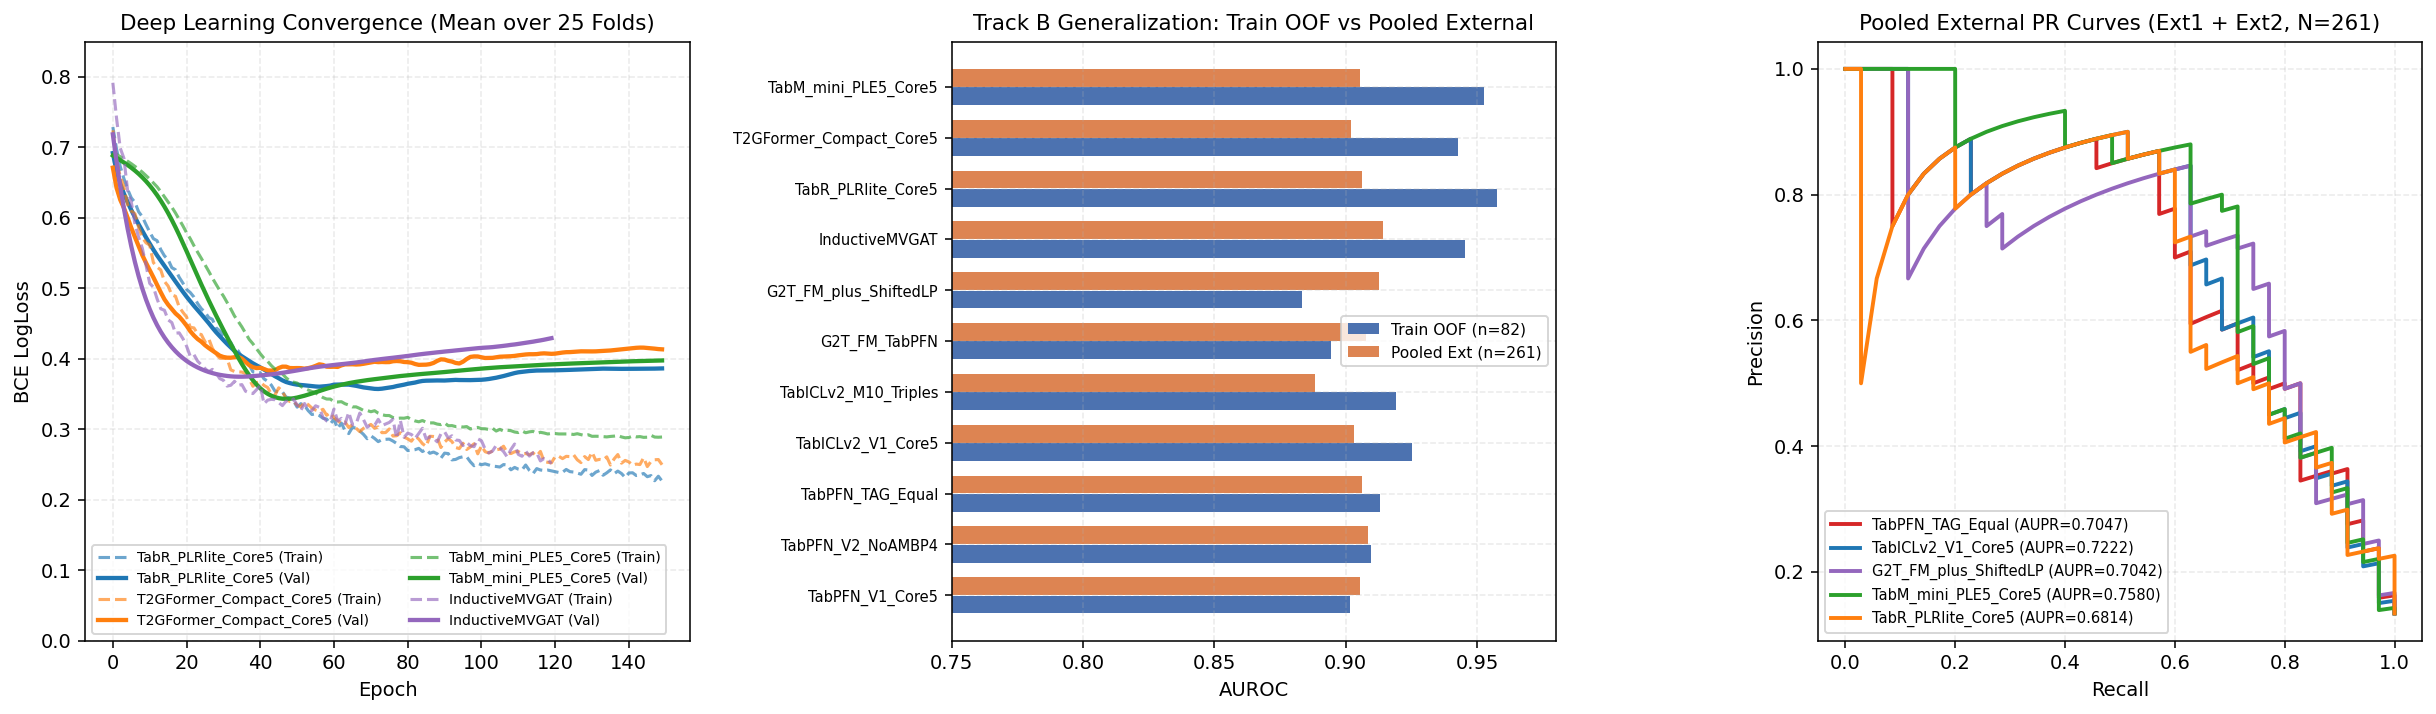


[TRACK B COMPLETE] Все артефакты сохранены и перепакованы в `artifacts.zip`


In [10]:
track_b_export_pool = {
    "TabPFN_V1_Core5": tfm_results["TabPFN__V1_Core5"],
    "TabPFN_V2_NoAMBP4": tfm_results["TabPFN__V2_NoAMBP4"],
    "TabPFN_TAG_Equal": tfm_results["TabPFN__TAG_Equal_5Views"],
    "TabPFN_TAG_ES": tfm_results["TabPFN__TAG_ES_5Views"],
    "TabICLv2_V1_Core5": tfm_results["TabICLv2__V1_Core5"],
    "TabICLv2_M10_Triples": tfm_results["TabICLv2__M10_Compact_Triples"],
    "TabICLv2_TAG_Equal": tfm_results["TabICLv2__TAG_Equal_5Views"],
    "G2T_FM_TabPFN": {"oof_logits": b3_results["G2T_FM_TabPFN"][0], "test_logits_bagged": b3_results["G2T_FM_TabPFN"][1]},
    "G2T_FM_TabICLv2": {"oof_logits": b3_results["G2T_FM_TabICLv2"][0], "test_logits_bagged": b3_results["G2T_FM_TabICLv2"][1]},
    "G2T_FM_plus_ShiftedLP": {"oof_logits": b3_results["G2T_FM_plus_ShiftedLP"][0], "test_logits_bagged": b3_results["G2T_FM_plus_ShiftedLP"][1]},
    "InductiveMVGAT": {"oof_logits": b3_results["InductiveMVGAT"][0], "test_logits_bagged": b3_results["InductiveMVGAT"][1]},
    "TabR_PLRlite_Core5": dl_results["TabR_PLRlite_Core5"],
    "T2GFormer_Compact_Core5": dl_results["T2GFormer_Compact_Core5"],
    "TabM_mini_PLE5_Core5": dl_results["TabM_mini_PLE5_Core5"],
    "TabM_mini_Periodic_Core5": dl_results["TabM_mini_Periodic_Core5"],
    "TabM_mini_PLE5_NoAMBP4": dl_results["TabM_mini_PLE5_NoAMBP4"],
}

base_test_path = TRACK_A_DIR / "test_Baseline_LogReg_5Markers.parquet"
base_probs_holdout = pd.read_parquet(base_test_path)["test_prob_bagged"].values if base_test_path.exists() else None

eval_slices = [
    ("Internal_Val (n=83)", m_int),
    ("External_Val1 (n=127)", m_ext1),
    ("External_Val2 (n=134)", m_ext2),
    ("Pooled_Ext (Ext1+Ext2, n=261)", m_ext1 | m_ext2),
    ("All_Holdout (n=344)", np.ones_like(m_int, dtype=bool)),
]

rows_exam_b = []
for m_label, obj in track_b_export_pool.items():
    oof_l = obj["oof_logits"]
    bag_l = obj["test_logits_bagged"]
    ref_l = obj.get("test_logits_refit", None)
    save_track_b_artifact(m_label, oof_l, bag_l, ref_l)

    p_hold = expit(bag_l)
    p_hold_em = np.zeros_like(p_hold)
    for cm in [m_int, m_ext1, m_ext2]:
        p_hold_em[cm], _ = adjust_probs_saerens(p_hold[cm], pi_train=PI_TRAIN, alpha_reg=2.0)

    for s_name, s_mask in eval_slices:
        m_raw = compute_clinical_metrics(y_holdout[s_mask], p_hold[s_mask])
        m_em  = compute_clinical_metrics(y_holdout[s_mask], p_hold_em[s_mask])
        p_dl = delong_roc_test(y_holdout[s_mask], p_hold[s_mask], base_probs_holdout[s_mask])[1] if base_probs_holdout is not None else np.nan
        rows_exam_b.append({
            "Model": m_label,
            "Cohort": s_name,
            "AUROC": round(m_raw["AUROC"], 4),
            "AUPR": round(m_raw["AUPR"], 4),
            "F1_EM": round(m_em["F1"], 4),
            "PPV_EM": round(m_em["PPV"], 4),
            "Brier_EM": round(m_em["Brier"], 4),
            "DeLong_p_vs_Base": round(p_dl, 4) if not np.isnan(p_dl) else np.nan,
        })

df_exam_b = pd.DataFrame(rows_exam_b)
print("\n=== ЭКЗАМЕН ТРЕКА B НА POOLED_EXT (Ext1+Ext2, N=261) И INTERNAL (N=83) ===")
print(df_exam_b[df_exam_b["Cohort"].isin(["Internal_Val (n=83)", "External_Val1 (n=127)", "Pooled_Ext (Ext1+Ext2, n=261)"])].to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))

ax = axes[0]
for name_dl, col_dl in [
    ("TabR_PLRlite_Core5", "#1f77b4"),
    ("T2GFormer_Compact_Core5", "#ff7f0e"),
    ("TabM_mini_PLE5_Core5", "#2ca02c"),
]:
    ax.plot(dl_results[name_dl]["tr_curve"], ls="--", lw=1.6, color=col_dl, alpha=0.65, label=f"{name_dl} (Train)")
    ax.plot(dl_results[name_dl]["val_curve"], ls="-", lw=2.2, color=col_dl, label=f"{name_dl} (Val)")
ax.plot(mvgat_curves[0], ls="--", lw=1.6, color="#9467bd", alpha=0.65, label="InductiveMVGAT (Train)")
ax.plot(mvgat_curves[1], ls="-", lw=2.2, color="#9467bd", label="InductiveMVGAT (Val)")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE LogLoss")
ax.set_ylim(0.0, 0.85)
ax.set_title("Deep Learning Convergence (Mean over 25 Folds)")
ax.legend(fontsize=7.2, ncol=2)

ax = axes[1]
summary_plot = []
for m_lbl in ["TabPFN_V1_Core5", "TabPFN_V2_NoAMBP4", "TabPFN_TAG_Equal", "TabICLv2_V1_Core5", "TabICLv2_M10_Triples",
              "G2T_FM_TabPFN", "G2T_FM_plus_ShiftedLP", "InductiveMVGAT", "TabR_PLRlite_Core5", "T2GFormer_Compact_Core5", "TabM_mini_PLE5_Core5"]:
    oof_auc = roc_auc_score(y_train_82, expit(track_b_export_pool[m_lbl]["oof_logits"]))
    ext_auc = df_exam_b[(df_exam_b["Model"] == m_lbl) & (df_exam_b["Cohort"] == "Pooled_Ext (Ext1+Ext2, n=261)")]["AUROC"].values[0]
    summary_plot.append((m_lbl, oof_auc, ext_auc))
sp_df = pd.DataFrame(summary_plot, columns=["Model", "OOF_AUROC", "Ext_AUROC"])
y_pos = np.arange(len(sp_df))
ax.barh(y_pos - 0.18, sp_df["OOF_AUROC"], height=0.35, color="#4c72b0", label="Train OOF (n=82)")
ax.barh(y_pos + 0.18, sp_df["Ext_AUROC"], height=0.35, color="#dd8452", label="Pooled Ext (n=261)")
ax.set_yticks(y_pos)
ax.set_yticklabels(sp_df["Model"], fontsize=7.5)
ax.set_xlim(0.75, 0.98)
ax.set_xlabel("AUROC")
ax.set_title("Track B Generalization: Train OOF vs Pooled External")
ax.legend(fontsize=8)

ax = axes[2]
ext_pool_m = m_ext1 | m_ext2
y_ep = y_holdout[ext_pool_m]
for m_lbl, col_c in [
    ("TabPFN_TAG_Equal", "#d62728"),
    ("TabICLv2_V1_Core5", "#1f77b4"),
    ("G2T_FM_plus_ShiftedLP", "#9467bd"),
    ("TabM_mini_PLE5_Core5", "#2ca02c"),
    ("TabR_PLRlite_Core5", "#ff7f0e"),
]:
    p_ep = expit(track_b_export_pool[m_lbl]["test_logits_bagged"])[ext_pool_m]
    from sklearn.metrics import precision_recall_curve
    prec, rec, _ = precision_recall_curve(y_ep, p_ep)
    ap = average_precision_score(y_ep, p_ep)
    ax.plot(rec, prec, lw=2.0, color=col_c, label=f"{m_lbl} (AUPR={ap:.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Pooled External PR Curves (Ext1 + Ext2, N=261)")
ax.legend(fontsize=7.5, loc="lower left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "TrackB_Summary_Diagnostics.png", dpi=300)
plt.show()

df_b1_b2.to_csv(TRACK_B_DIR / "exp_b1_b2_tfm_cv.csv", index=False)
df_exam_b.to_csv(TRACK_B_DIR / "track_b_exam_summary.csv", index=False)

shutil.make_archive("artifacts", "zip", "artifacts")
print("\n[TRACK B COMPLETE] Все артефакты сохранены и перепакованы в `artifacts.zip`")